In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target_names[iris.target]

print('Dataset shape:', df.shape)
print('Species:', df['species'].unique())
print(df.head())

Dataset shape: (150, 5)
Species: <ArrowStringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


In [2]:
from sklearn.model_selection import train_test_split

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f'Training samples: {X_train.shape[0]}')
print(f'Testing samples: {X_test.shape[0]}')
print(f'Training class distribution: {dict(zip(*np.unique(y_train, return_counts=True)))}')

Training samples: 120
Testing samples: 30
Training class distribution: {np.int64(0): np.int64(40), np.int64(1): np.int64(40), np.int64(2): np.int64(40)}


In [3]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_model.fit(X_train, y_train)

print('Model training complete!')
print('Number of leaves in tree:', dt_model.get_n_leaves())
print('Tree depth:', dt_model.get_depth())

y_pred = dt_model.predict(X_test)
print('Actual labels:   ', y_test[:10])
print('Predicted labels:', y_pred[:10])

new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = dt_model.predict(new_flower)
prediction_proba = dt_model.predict_proba(new_flower)

print('\nPredicted species:', iris.target_names[prediction[0]])
print('Confidence:', prediction_proba)

Model training complete!
Number of leaves in tree: 5
Tree depth: 3
Actual labels:    [0 2 1 1 0 1 0 0 2 1]
Predicted labels: [0 2 1 1 0 1 0 0 2 1]

Predicted species: setosa
Confidence: [[1. 0. 0.]]


Accuracy: 96.67%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



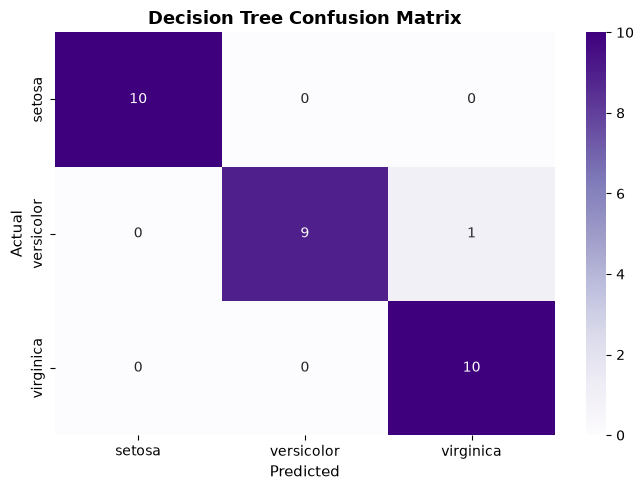

In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=iris.target_names))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names, ax=ax)
ax.set_title('Decision Tree Confusion Matrix', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted', fontsize=11)
ax.set_ylabel('Actual', fontsize=11)
plt.tight_layout()
plt.savefig('confusion_matrix_dt.png', dpi=150)
plt.show()

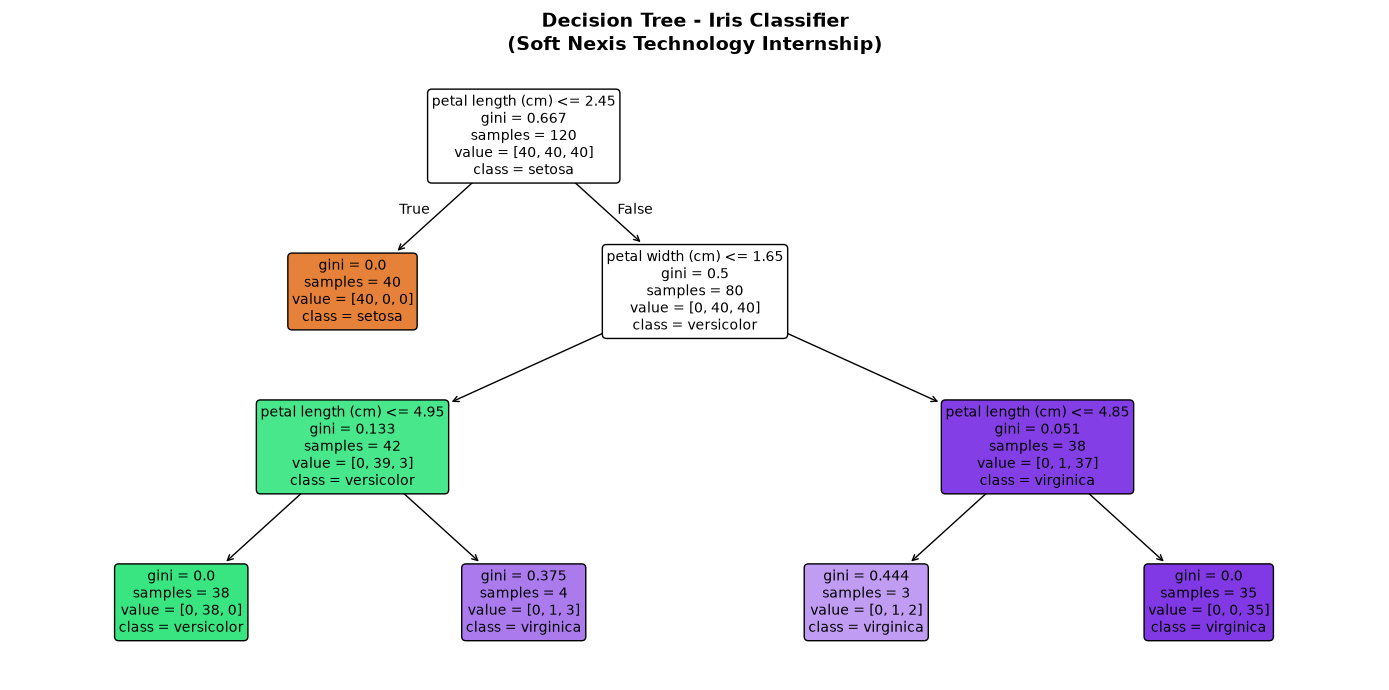

In [5]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(dt_model,
          feature_names=iris.feature_names,
          class_names=iris.target_names,
          filled=True,
          rounded=True,
          fontsize=10,
          ax=ax)
ax.set_title('Decision Tree - Iris Classifier\n(Soft Nexis Technology Internship)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('decision_tree_visual.png', dpi=150, bbox_inches='tight')
plt.show()

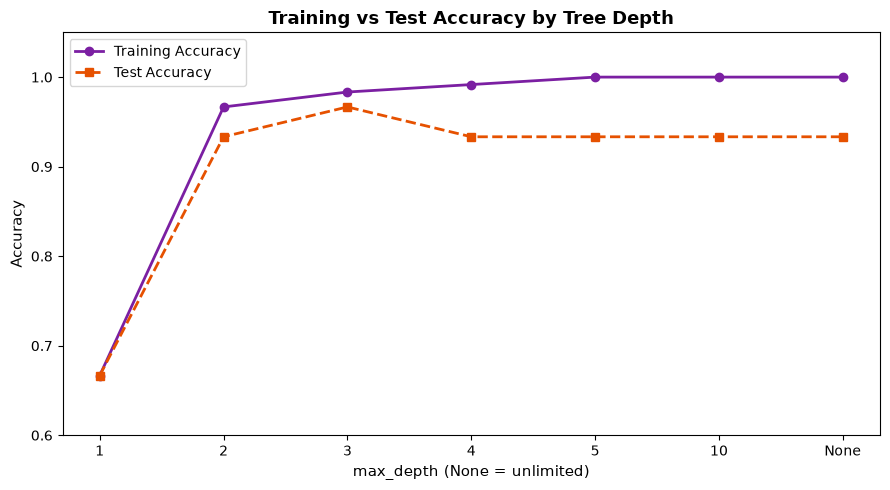

In [6]:
depths = [1, 2, 3, 4, 5, 10, None]
train_acc = []
test_acc = []

for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(9, 5))
depth_labels = [str(d) for d in depths]
ax.plot(depth_labels, train_acc, 'o-', label='Training Accuracy', color='#7B1FA2', linewidth=2)
ax.plot(depth_labels, test_acc, 's--', label='Test Accuracy', color='#E65100', linewidth=2)
ax.set_title('Training vs Test Accuracy by Tree Depth', fontsize=13, fontweight='bold')
ax.set_xlabel('max_depth (None = unlimited)', fontsize=11)
ax.set_ylabel('Accuracy', fontsize=11)
ax.legend(fontsize=10)
ax.set_ylim(0.6, 1.05)
plt.tight_layout()
plt.savefig('depth_vs_accuracy.png', dpi=150)
plt.show()

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print(f'Random Forest Test Accuracy: {accuracy_score(y_test, y_pred_rf) * 100:.2f}%\n')

dt_cv = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=42), X, y, cv=5, scoring='accuracy')
rf_cv = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X, y, cv=5, scoring='accuracy')

print('Decision Tree CV Accuracy:')
print(f'  Each fold: {dt_cv.round(3)}')
print(f'  Mean: {dt_cv.mean():.3f} | Std: {dt_cv.std():.3f}')

print('\nRandom Forest CV Accuracy:')
print(f'  Each fold: {rf_cv.round(3)}')
print(f'  Mean: {rf_cv.mean():.3f} | Std: {rf_cv.std():.3f}')

Random Forest Test Accuracy: 93.33%

Decision Tree CV Accuracy:
  Each fold: [0.967 0.967 0.933 1.    1.   ]
  Mean: 0.973 | Std: 0.025

Random Forest CV Accuracy:
  Each fold: [0.967 0.967 0.933 0.967 1.   ]
  Mean: 0.967 | Std: 0.021


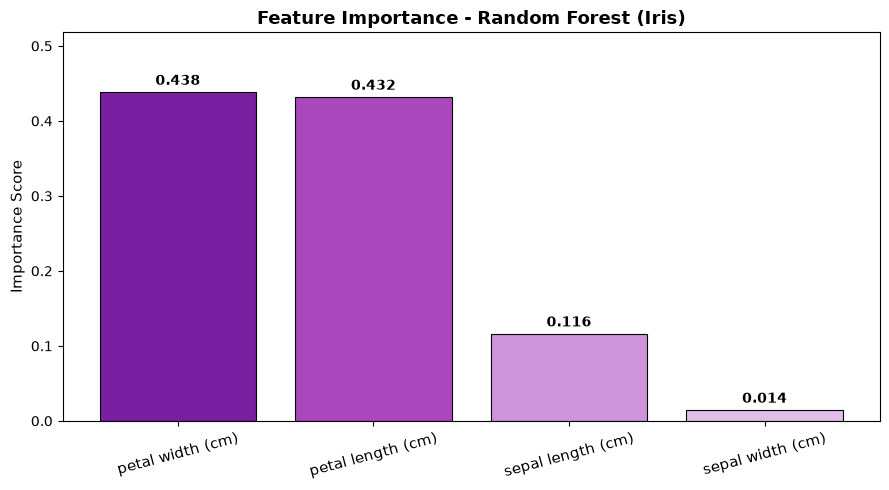

In [8]:
importances = rf_model.feature_importances_
feature_names = iris.feature_names
sorted_idx = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(range(4), importances[sorted_idx],
              color=['#7B1FA2', '#AB47BC', '#CE93D8', '#E1BEE7'],
              edgecolor='black', linewidth=0.8)
ax.set_xticks(range(4))
ax.set_xticklabels([feature_names[i] for i in sorted_idx], rotation=15, fontsize=11)
ax.set_title('Feature Importance - Random Forest (Iris)', fontsize=13, fontweight='bold')
ax.set_ylabel('Importance Score', fontsize=11)
ax.set_ylim(0, max(importances) + 0.08)

for bar, imp in zip(bars, importances[sorted_idx]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f'{imp:.3f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

Decision Tree (depth=3): 0.973 ± 0.025
Random Forest (100 trees): 0.967 ± 0.021
Gradient Boosting: 0.960 ± 0.033
K-Nearest Neighbors: 0.973 ± 0.025
Logistic Regression: 0.973 ± 0.025


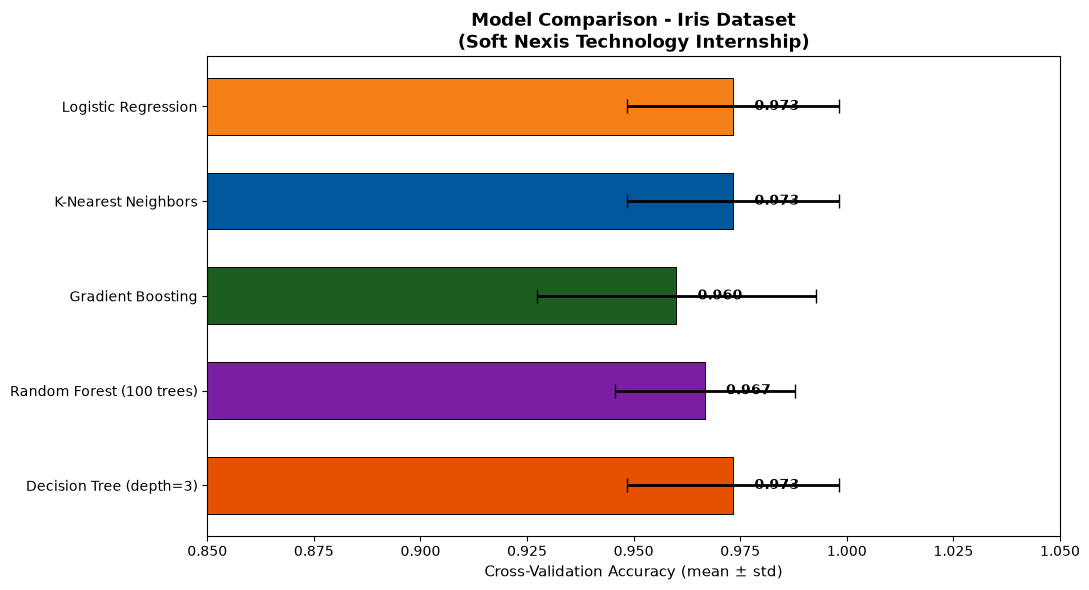

In [9]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

models = {
    'Decision Tree (depth=3)': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest (100 trees)': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression': LogisticRegression(max_iter=200, random_state=42)
}

results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    results[name] = scores
    print(f'{name}: {scores.mean():.3f} ± {scores.std():.3f}')

fig, ax = plt.subplots(figsize=(11, 6))
names = list(results.keys())
means = [results[n].mean() for n in names]
stds = [results[n].std() for n in names]
colors_bar = ['#E65100', '#7B1FA2', '#1B5E20', '#01579B', '#F57F17']

bars = ax.barh(names, means, xerr=stds, color=colors_bar,
               edgecolor='black', linewidth=0.7, height=0.6,
               error_kw={'capsize': 5, 'linewidth': 2})

for bar, mean in zip(bars, means):
    ax.text(mean + 0.005, bar.get_y() + bar.get_height() / 2,
            f'{mean:.3f}', va='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Cross-Validation Accuracy (mean ± std)', fontsize=11)
ax.set_title('Model Comparison - Iris Dataset\n(Soft Nexis Technology Internship)',
             fontsize=13, fontweight='bold')
ax.set_xlim(0.85, 1.05)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

Fitting 5 folds for each of 36 candidates, totalling 180 fits

Best Parameters: {'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 50}
Best CV Accuracy: 95.83%
FINAL MODEL EVALUATION REPORT
Soft Nexis Technology ML Internship
Algorithm     : Random Forest (Tuned)
Test Accuracy : 96.67%

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



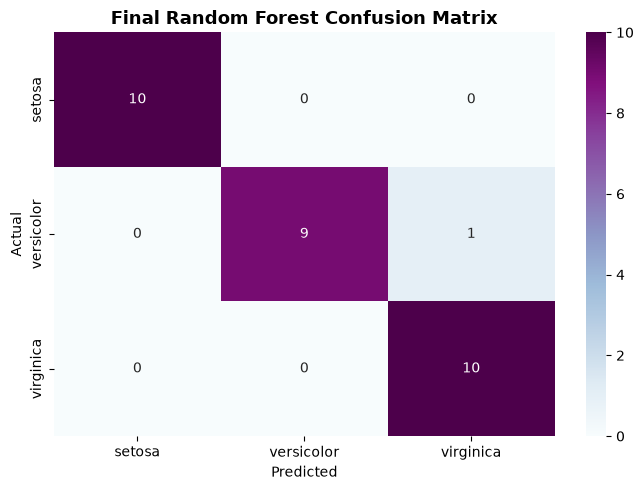

In [10]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

print('\nBest Parameters:', grid_search.best_params_)
print(f'Best CV Accuracy: {grid_search.best_score_ * 100:.2f}%')

best_model = grid_search.best_estimator_
y_final_pred = best_model.predict(X_test)

print('=' * 55)
print('FINAL MODEL EVALUATION REPORT')
print('Soft Nexis Technology ML Internship')
print('=' * 55)
print('Algorithm     : Random Forest (Tuned)')
print(f'Test Accuracy : {accuracy_score(y_test, y_final_pred) * 100:.2f}%\n')
print(classification_report(y_test, y_final_pred, target_names=iris.target_names))

fig, ax = plt.subplots(figsize=(7, 5))
cm_final = confusion_matrix(y_test, y_final_pred)
sns.heatmap(cm_final, annot=True, fmt='d', cmap='BuPu',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names, ax=ax)
ax.set_title('Final Random Forest Confusion Matrix', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig('final_confusion_matrix.png', dpi=150)
plt.show()

Understanding Overfitting and How Random Forest Solves It

Overfitting occurs in machine learning when a model learns the training dataset too closely, memorizing specific data points and random noise rather than capturing the underlying patterns that generalize to new, unseen examples. In Task 1, we observed this behavior when experimenting with the max_depth parameter of a single Decision Tree on the Iris dataset. When the tree depth was unrestricted (max_depth=None), the model achieved 100% accuracy on the training set because it kept splitting nodes until every training sample was isolated. However, because a deep single tree tailors its decision boundaries to the quirks of one specific 80% training split, its accuracy on unseen test data plateaus or drops when encountering slightly different flower measurements.

A Random Forest solves this problem through ensemble learning—combining the predictions of many independent Decision Trees (100 trees in our model) rather than relying on a single tree. Instead of training every tree on the exact same dataset, Random Forest introduces randomness in two ways. First, through bootstrap aggregating (bagging), each tree is trained on a different random subset of the training samples. Second, at each split in a tree, the algorithm considers only a random subset of features rather than all four measurements.

Because each tree sees slightly different data and features, individual trees make different errors. When making a final prediction, the Random Forest takes a majority vote across all 100 trees. This averaging effect cancels out the individual overfitting mistakes of single trees, resulting in smoother decision boundaries, lower variance across cross-validation folds, and more reliable accuracy on new data.